# 03 · Similarity search, ranking & evaluation

Steps 3–5 of the approach:

3. **Similarity matching** - query image → embedding → cosine search → Top-K products
4. **Ranking & filtering** - rank by similarity; filter by category, price range, availability
5. **Evaluation** - Precision@K, Recall@K and visual inspection

Everything here goes through `src/search_engine.py`, the same code path the Streamlit app uses.

FAISS stores one vector per **photo**, but a shopper wants **products**. The engine fetches more
photo hits than K, groups them by product and keeps each product's best-matching photo.

In [1]:
import sys, time
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from IPython.display import Image as ShowImage, display

import config
from src import database, evaluation
from src.search_engine import SearchFilters, VisualSearchEngine

sns.set_theme(style="whitegrid", context="notebook")
engine = VisualSearchEngine(config.DEFAULT_MODEL, "hnsw")
catalog = engine.catalog
print(f"Engine: {engine.model_name} / {engine.index_type} | {engine.index.ntotal:,} photo vectors | "
      f"{engine.num_products:,} products")

Engine: resnet50 / hnsw | 58,891 photo vectors | 11,311 products


In [2]:
def show_results(query_imgs, results, title):
    """Query photo(s) on the left, ranked product results (best photo) on the right."""
    n = len(query_imgs) + len(results)
    fig, axes = plt.subplots(1, n, figsize=(1.9 * n, 2.4))
    for i, img in enumerate(query_imgs):
        axes[i].imshow(img)
        axes[i].set_title(title if i == 0 else "", fontsize=8, fontweight="bold", loc="left")
    for ax, (_, r) in zip(axes[len(query_imgs):], results.iterrows()):
        with Image.open(config.CLEAN_IMAGE_DIR / r["image_file"]) as img:
            ax.imshow(img.convert("RGB"))
        ax.set_title(f"#{r['rank']} {r['category']}\ncos={r['similarity']:.3f} ₹{r['price']:,}", fontsize=7.5)
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

def photos_of(product_id, n=3):
    return [Image.open(config.CLEAN_IMAGE_DIR / f).convert("RGB") for f in database.get_product_images(product_id)[:n]]

## 1. "Similar items" for a catalog product

`similar_to_product` builds the query from the **mean of all the product's photo embeddings**
(a multi-view product vector), and excludes the product itself from the results. Left: up to
three photos of the query product. Right: the top-6 *other* products.

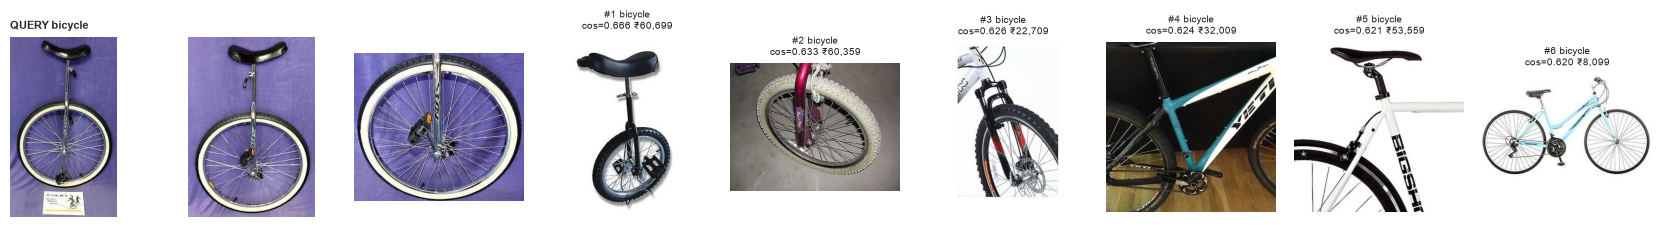

Bicycle #0402 - search + ranking 16.7 ms


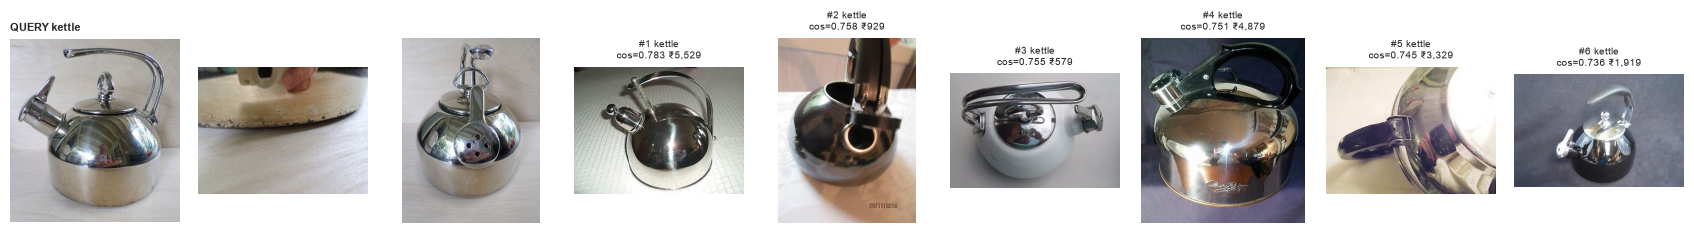

Kettle #0776 - search + ranking 11.5 ms


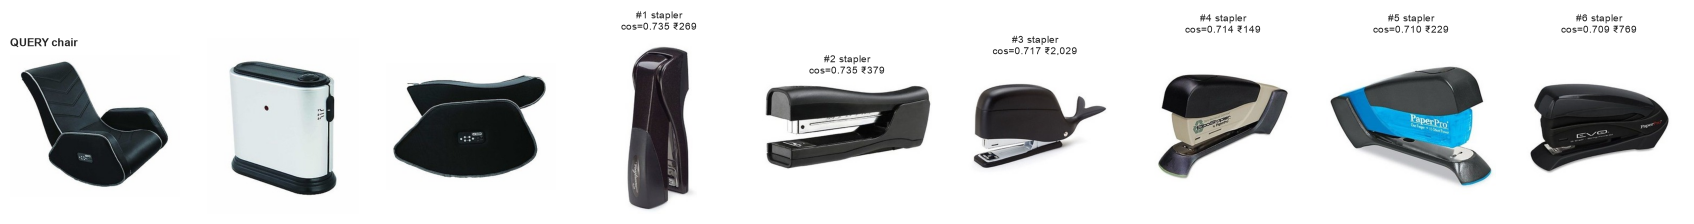

Chair #0027 - search + ranking 10.3 ms


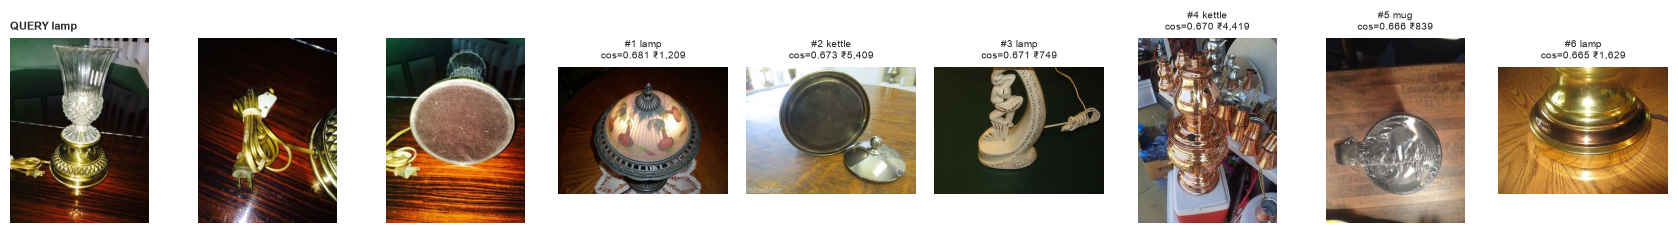

Lamp #0898 - search + ranking 13.6 ms


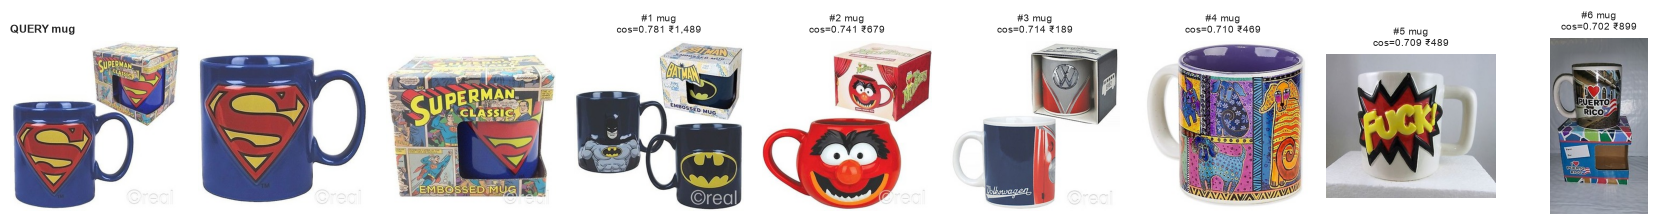

Mug #0615 - search + ranking 20.9 ms


In [3]:
rng = np.random.default_rng(5)
multi_view = catalog.groupby("product_id").filter(lambda g: len(g) >= 3)
for category in ["bicycle", "kettle", "chair", "lamp", "mug"]:
    pid = rng.choice(multi_view.loc[multi_view["category"] == category, "product_id"].unique())
    out = engine.similar_to_product(pid, top_k=6)
    show_results(photos_of(pid), out.results, f"QUERY {category}")
    print(f"{engine.product(pid)['product_name']} - search + ranking {out.latency_ms:.1f} ms")

## 2. Image search with a shopper's own photo

A real upload is never pixel-identical to a catalog image. To imitate one, I take a catalog
photo and randomly crop, rotate and colour-shift it, then search with the result. The right
answer is the product the photo came from.

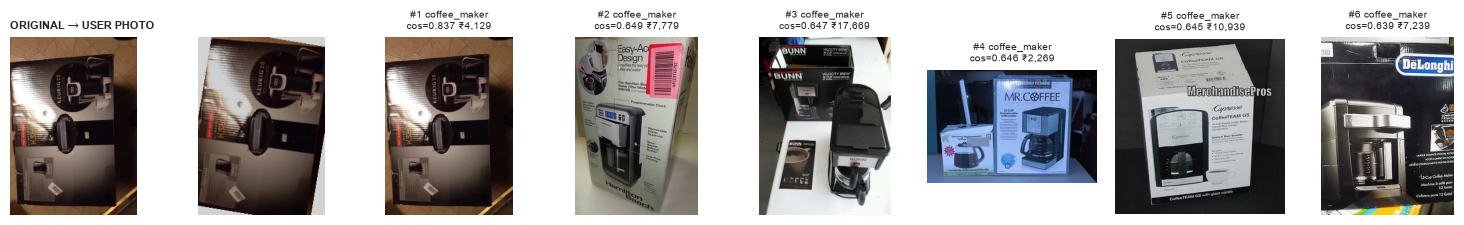

Coffee Maker #0695: correct product at rank 1 | CNN 92 ms | search + ranking 9.9 ms


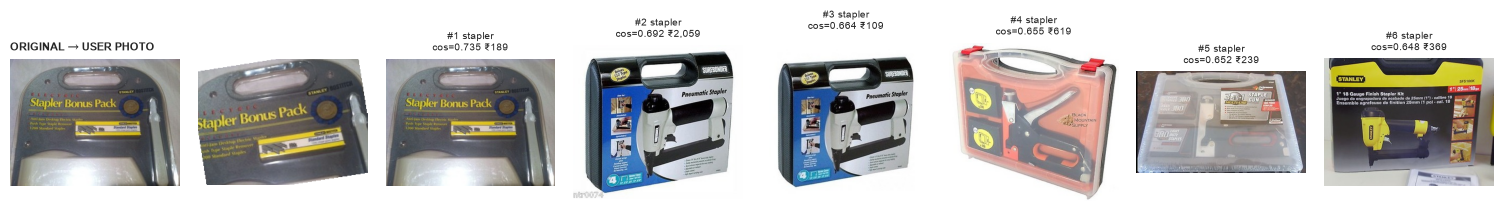

Stapler #0248: correct product at rank 1 | CNN 64 ms | search + ranking 10.4 ms


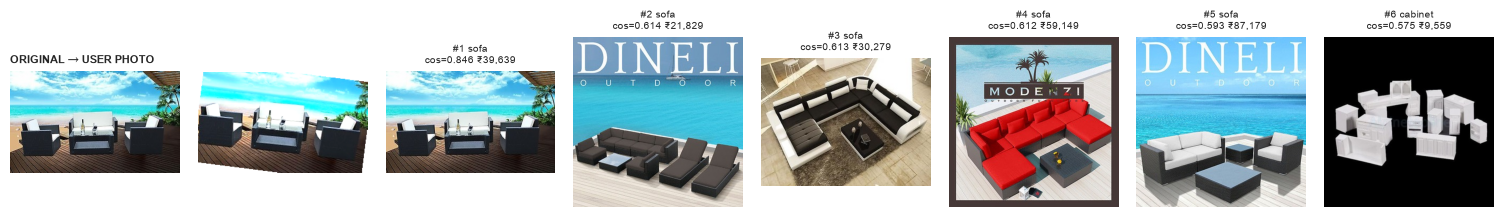

Sofa #0173: correct product at rank 1 | CNN 102 ms | search + ranking 9.1 ms


In [4]:
rng = np.random.default_rng(11)
for category in ["coffee_maker", "stapler", "sofa"]:
    row = catalog[catalog["category"] == category].sample(1, random_state=int(rng.integers(1e6))).iloc[0]
    with Image.open(config.CLEAN_IMAGE_DIR / row["image_file"]) as img:
        original = img.convert("RGB")
    user_photo = evaluation.simulate_user_photo(original, rng)
    out = engine.search_image(user_photo, top_k=6)
    show_results([original, user_photo], out.results, "ORIGINAL → USER PHOTO")
    hit = out.results.index[out.results["product_id"] == row["product_id"]]
    print(f"{row['product_name']}: correct product at rank {hit[0] + 1 if len(hit) else '>6'} | "
          f"CNN {out.embed_ms:.0f} ms | search + ranking {out.latency_ms:.1f} ms")

## 3. Ranking & filtering

Filters are pushed **into** the FAISS search with an ID selector, so the engine still returns K
products when a filter is selective (instead of fetching K and discarding most of them).
Products are ranked by cosine similarity of their best photo, ties broken by rating.

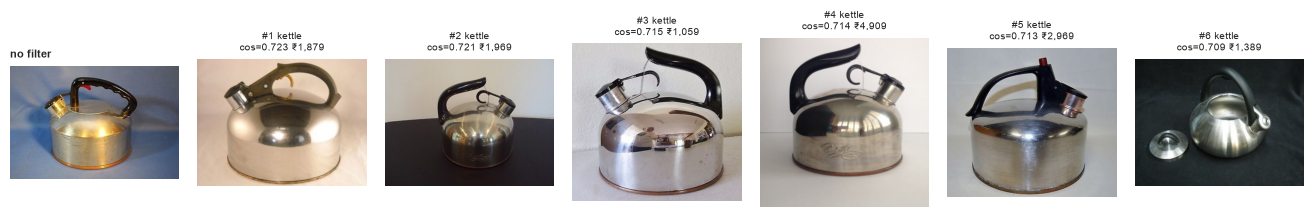

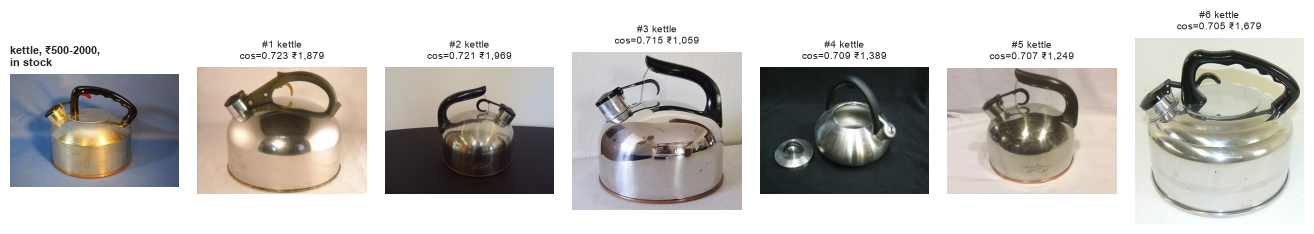

,rank,product_id,product_name,category,similarity,price,in_stock
0,1,301648676449,Kettle #0543,kettle,0.7233,1879,1
1,2,291537899522,Kettle #0513,kettle,0.7206,1969,1
2,3,381354674521,Kettle #0873,kettle,0.7155,1059,1
3,4,351462055989,Kettle #0770,kettle,0.7093,1389,1
4,5,261991693146,Kettle #0273,kettle,0.7067,1249,1
5,6,391214805953,Kettle #0912,kettle,0.7054,1679,1


In [5]:
pid = multi_view.loc[multi_view["category"] == "kettle", "product_id"].iloc[10]
unfiltered = engine.similar_to_product(pid, top_k=6).results
f = SearchFilters(categories=["kettle"], price_range=(500, 2000), in_stock_only=True)
filtered = engine.similar_to_product(pid, top_k=6, filters=f).results

show_results(photos_of(pid, 1), unfiltered, "no filter")
show_results(photos_of(pid, 1), filtered, "kettle, ₹500-2000,\nin stock")
filtered[["rank", "product_id", "product_name", "category", "similarity", "price", "in_stock"]]

In [6]:
assert (filtered["category"] == "kettle").all()
assert filtered["price"].between(500, 2000).all()
assert filtered["in_stock"].astype(bool).all()
assert filtered["product_id"].is_unique and pid not in filtered["product_id"].values
assert filtered["similarity"].is_monotonic_decreasing
print("All filter constraints satisfied; one result per product; query excluded; sorted by similarity.")

All filter constraints satisfied; one result per product; query excluded; sorted by similarity.


## 4. Quantitative evaluation

**Protocol - leave-one-out over the whole catalog:** each of the 58,891 photos queries all the
others (HNSW index, top-20).

| Level | Relevant result | Metrics |
|---|---|---|
| **Product** | another photo of the *same eBay listing* | Precision@K, Recall@K, Hit@K, mAP@K |
| **Category** | a photo from the same category | Precision@K |

Two "recall" definitions are reported for the product level:
* **classic Recall@K** = same-product photos found in top-K / all other photos of that product
* **Hit@K** = at least one same-product photo in top-K - the metric the SOP / metric-learning
  literature calls "Recall@K". I use it as the headline **Product Recall@K**.

Product Precision@K is capped by the number of photos a listing has (median 4-5), so it
naturally falls as K grows.

In [7]:
%%time
metrics = evaluation.run_evaluation()
models = metrics["models"]

CPU times: total: 22min 7s
Wall time: 1min 41s


In [8]:
rows = []
for m, r in models.items():
    o = r["retrieval"]["overall"]
    for k in config.EVAL_K_VALUES:
        rows.append({"model": m, "K": k, "product P@K": o[f"product_P@{k}"], "product R@K (classic)": o[f"product_R@{k}"],
                     "product R@K (hit rate)": o[f"product_Hit@{k}"], "product mAP@K": o[f"product_mAP@{k}"],
                     "category P@K": o[f"category_P@{k}"]})
table = pd.DataFrame(rows).set_index(["model", "K"])
table.style.format("{:.3f}").background_gradient(cmap="Greens", axis=None)

Random baseline - category P@K : 0.088
Random baseline - product R@1  : 0.000071


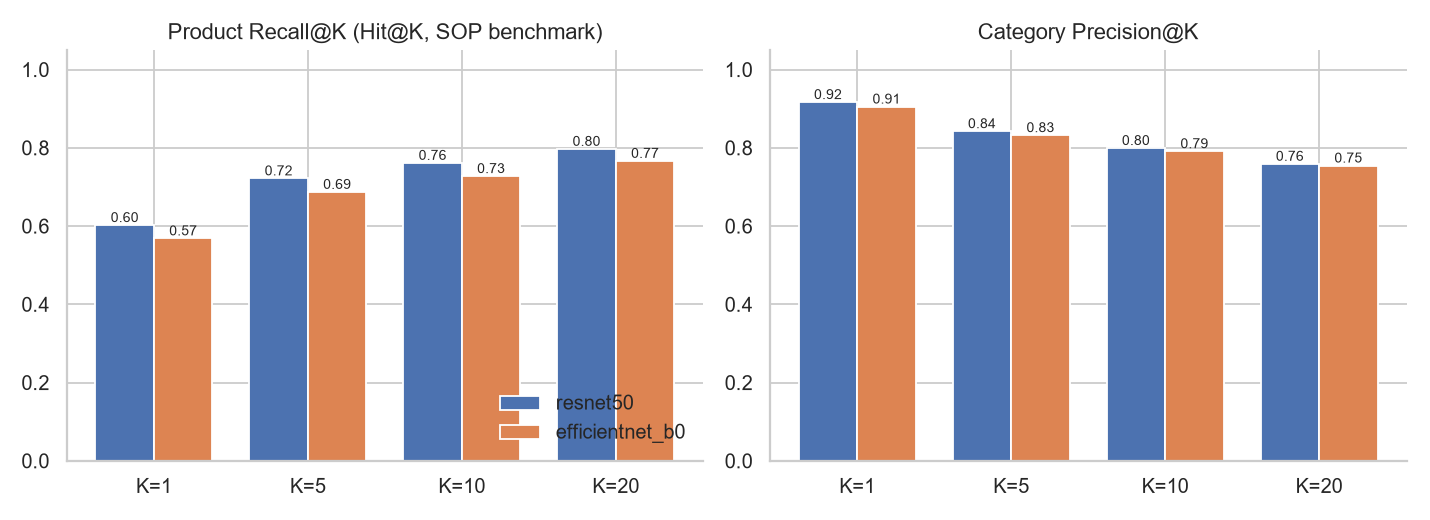

In [9]:
cat_share = catalog["category"].value_counts(normalize=True)
photos_per_product = catalog.groupby("product_id").size()
print(f"Random baseline - category P@K : {(cat_share ** 2).sum():.3f}")
print(f"Random baseline - product R@1  : {((photos_per_product - 1) / (len(catalog) - 1)).mean():.6f}")
display(ShowImage(filename=str(config.FIGURES_DIR / "model_comparison.png")))

**ResNet50 (with GeM pooling) is the best model at every K and on every metric.**

* **Product Recall@1 = 0.602**: for 60 % of the 58,593 photos that have a sibling, the single
  closest photo in a 58,891-photo catalog is *another photo of the same listing*. A random
  ranking gets 0.00007 here.
* **Product Recall@10 = 0.761**: a matching photo of the same listing is in the top 10 for
  three out of four queries.
* **Category Precision@1 = 0.917, @10 = 0.799**, against a random baseline of 0.088.
* EfficientNet-B0 trails by about 0.03 on product metrics. It is still a good choice when
  speed matters: smaller vectors (1280-d) and ~1.4× faster search.

For reference, before the GeM change ResNet50 with plain average pooling scored product
Recall@1 = 0.559, below EfficientNet-B0. The +0.043 from one pooling layer is the largest
single improvement in the project.

### Per-category performance

In [10]:
best = metrics["best_model"]
per_cat = pd.DataFrame(models[best]["retrieval"]["per_category"]).T
per_cat = per_cat[["product_Hit@1", "product_Hit@10", "product_AP@10", "category_P@1", "category_P@10"]]
per_cat.columns = ["product R@1", "product R@10", "product mAP@10", "category P@1", "category P@10"]
per_cat.sort_values("product R@1", ascending=False).style.format("{:.3f}").background_gradient(cmap="RdYlGn", vmin=0, vmax=1)

,product R@1,product R@10,product mAP@10,category P@1,category P@10
lamp,0.686,0.827,0.405,0.909,0.770
table,0.680,0.818,0.412,0.872,0.638
stapler,0.658,0.827,0.377,0.951,0.850
chair,0.650,0.800,0.347,0.885,0.717
mug,0.639,0.758,0.332,0.963,0.909
cabinet,0.623,0.778,0.288,0.918,0.824
toaster,0.592,0.759,0.331,0.906,0.737
sofa,0.576,0.763,0.328,0.908,0.788
fan,0.555,0.762,0.284,0.898,0.768
kettle,0.553,0.701,0.247,0.916,0.844


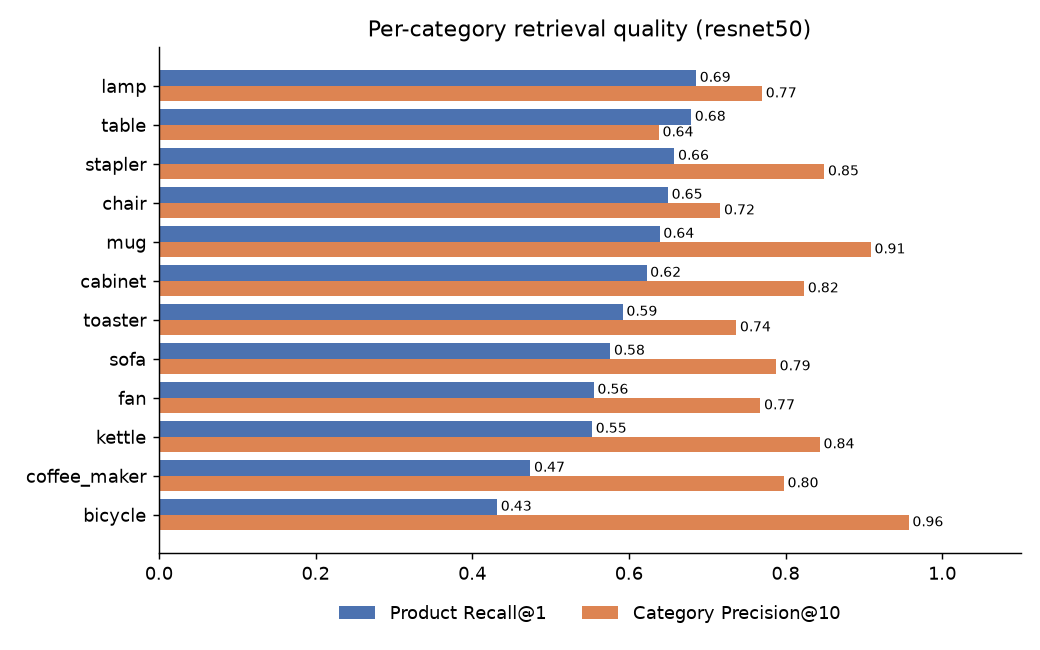

In [11]:
display(ShowImage(filename=str(config.FIGURES_DIR / f"per_category_{best}.png")))

### Which categories get confused?

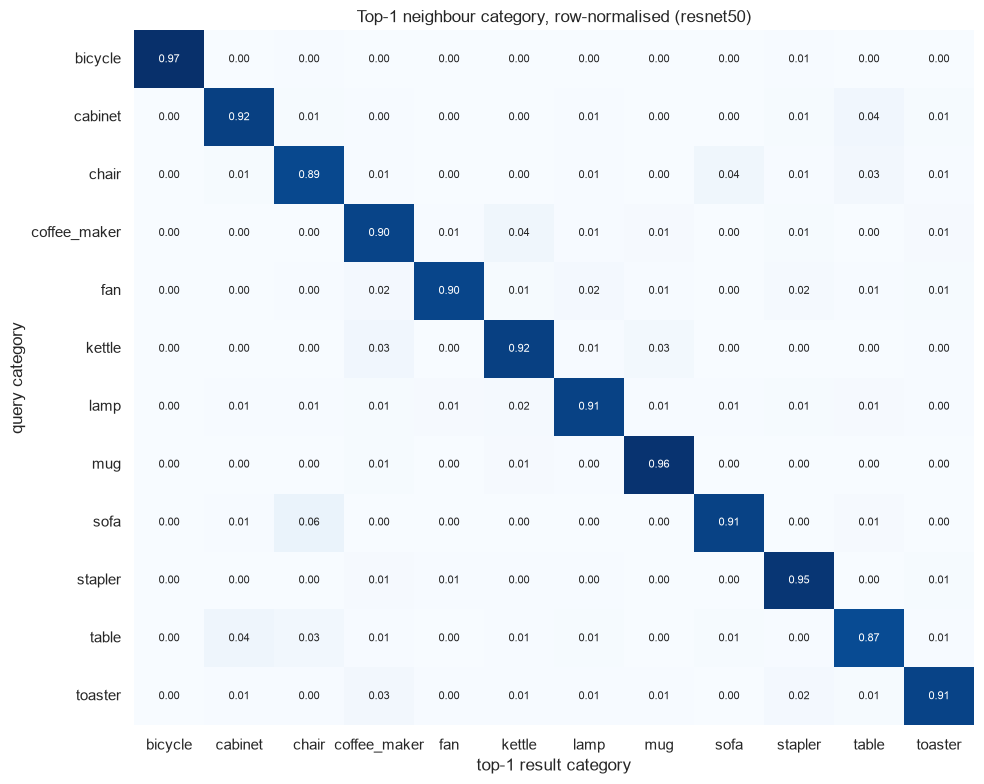

Largest confusions:
query category  top-1 result category
sofa            chair                    0.063
table           cabinet                  0.042
coffee_maker    kettle                   0.040
chair           sofa                     0.040
cabinet         table                    0.035
kettle          coffee_maker             0.035


In [12]:
nn1 = evaluation.leave_one_out_search(engine.index, np.load(config.embeddings_path(engine.model_name)), 1)[:, 0]
labels = catalog["category"].to_numpy()
confusion = pd.crosstab(pd.Series(labels, name="query category"),
                        pd.Series(labels[nn1], name="top-1 result category"), normalize="index")
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(confusion, annot=True, fmt=".2f", cmap="Blues", cbar=False, ax=ax, annot_kws={"size": 8})
ax.set_title(f"Top-1 neighbour category, row-normalised ({engine.model_name})")
plt.tight_layout()
plt.show()
off = confusion.where(~np.eye(len(confusion), dtype=bool)).stack().sort_values(ascending=False).head(6)
print("Largest confusions:\n" + off.round(3).to_string())

**Reading the per-category results**

* **Bicycle is the most interesting row.** It has the *highest* category precision (0.96;
  bikes only look like bikes) but the *lowest* product Recall@1 (0.43). One bike is very
  hard to tell from another, and bicycle listings include the most detail shots (saddles,
  gears, frames).
* **Coffee makers and kettles** have a similar pattern: lots of near-identical
  stainless-steel and black-plastic products from different sellers.
* **Lamps, tables and staplers** have the best product recall. Their designs vary a lot, so
  the same item is easy to tell apart from the others.
* The category confusions make sense: **sofa → chair** (6 %), **table ↔ cabinet**,
  **coffee maker ↔ kettle**. These are pairs that share materials, settings and shapes.

## 5. Visual inspection

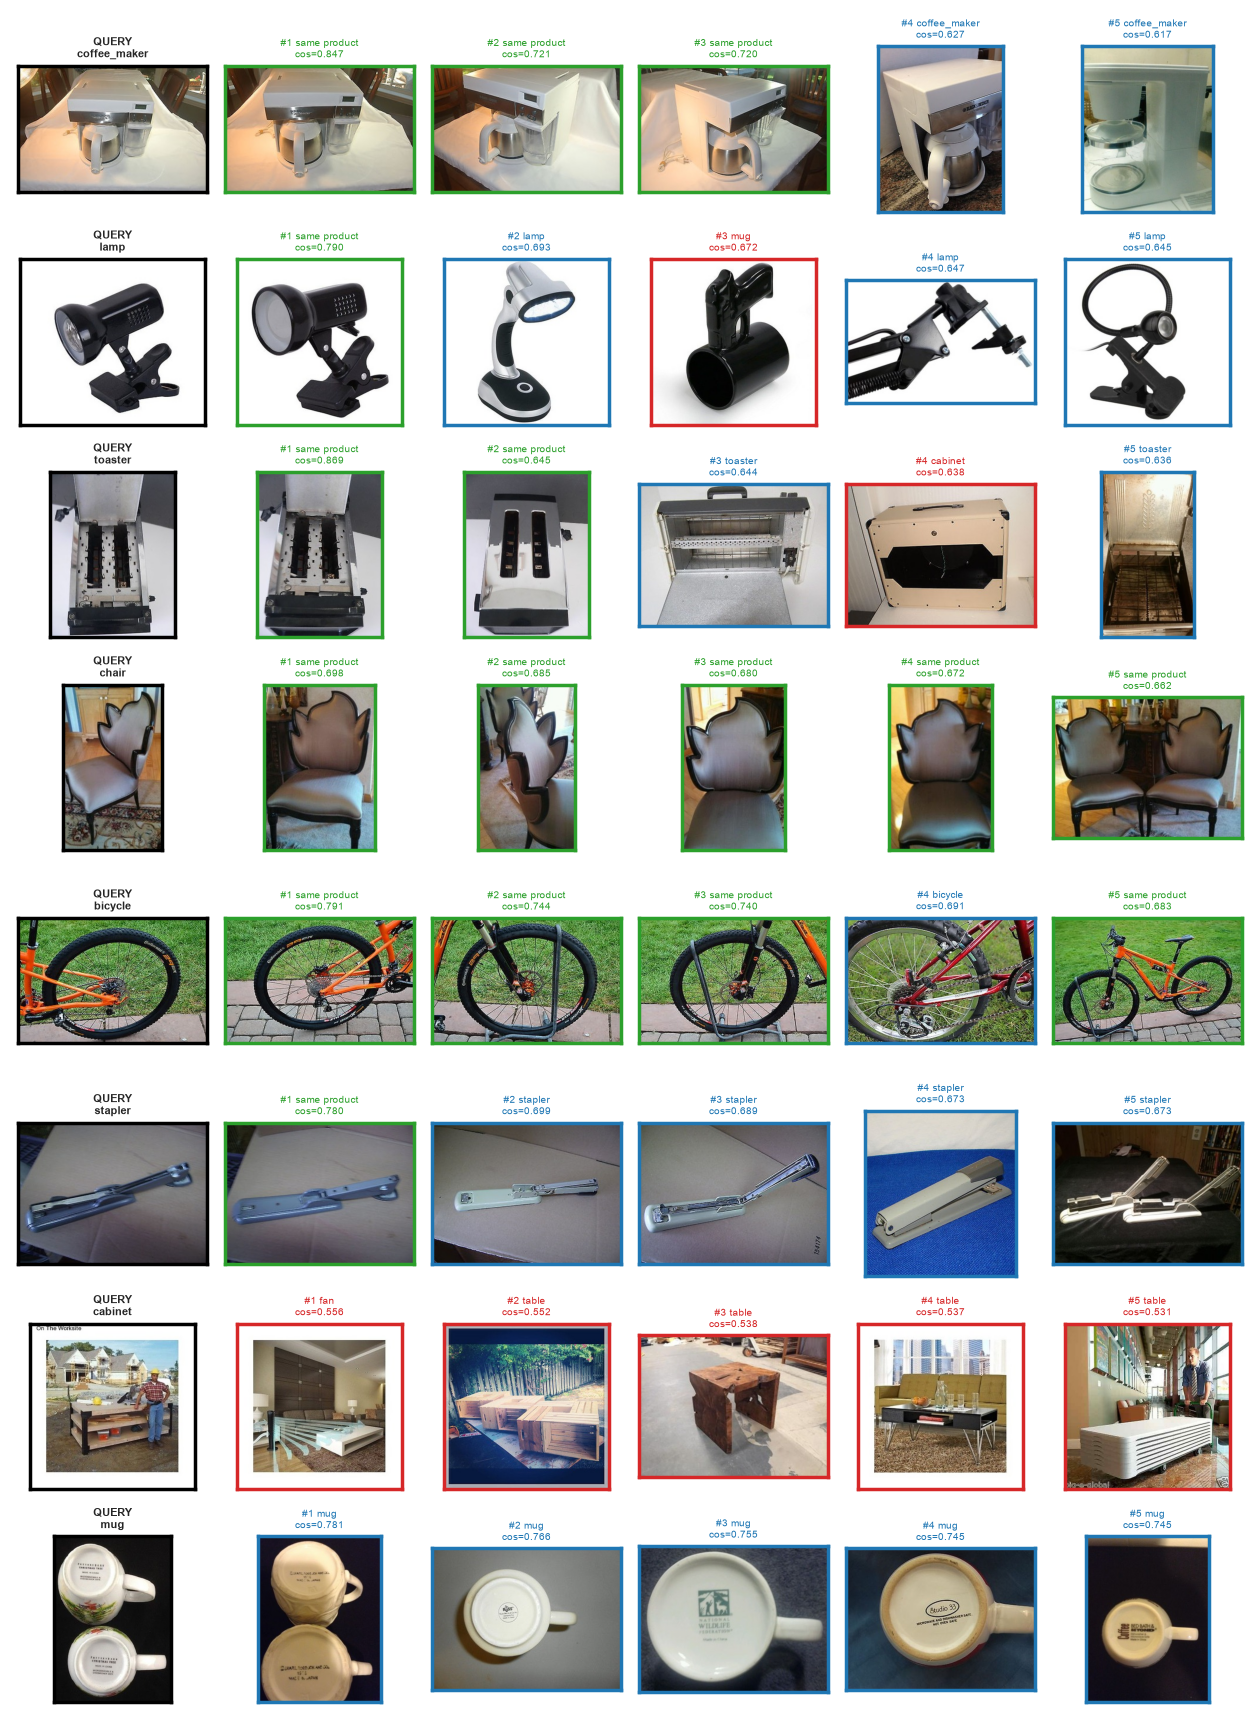

In [13]:
display(ShowImage(filename=str(config.FIGURES_DIR / f"visual_inspection_{best}.png")))

Green = another photo of the same product, blue = same category, red = different category.

* For the coffee maker, chair, bicycle and toaster queries, the top results are other
  photos of the **same listing** taken from different angles. The orange bicycle query is a
  wheel close-up, and the full-bike shot of the same listing still ranks in the top 5.
* Even "wrong" results are visually sensible. The black clip-lamp retrieves other black
  plastic clamp-shaped objects, and the mug-bottom query (a photo of the maker's stamp)
  retrieves other mug bottoms.
* The cabinet query is a real failure: a seller photo of a man standing next to the item in
  a yard. The CNN matches the outdoor wooden scene, not the cabinet.
* The "Similar items" demo in section 1 shows a pure *shape* failure: a glossy black curved
  gaming rocker chair returns staplers. The silhouette really is stapler-like. ImageNet
  features have no notion of scale, so a 1-metre chair and a 15-cm stapler can match.

### When does product retrieval fail?

Product Recall@1 by how many photos the listing has, and by which photo is the query
(view 0 is usually the seller's main shot):

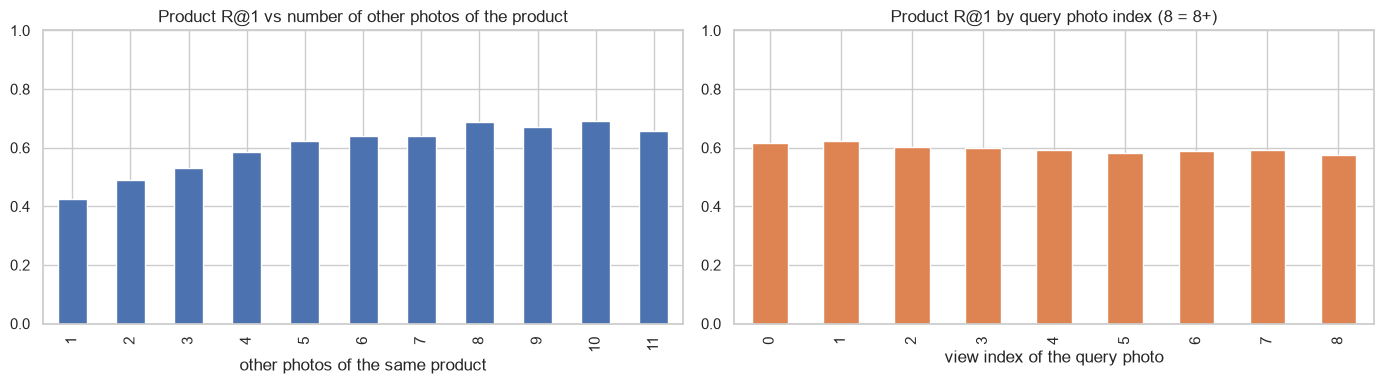

In [14]:
per_query = pd.read_csv(config.REPORTS_DIR / f"per_query_metrics_{best}.csv")
per_query = per_query[per_query["other_views"] > 0]
per_query["view"] = catalog["view_index"].to_numpy()[per_query["query_row"]]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
per_query.groupby("other_views")["product_Hit@1"].mean().plot.bar(ax=axes[0], color="#4C72B0")
axes[0].set_title("Product R@1 vs number of other photos of the product")
axes[0].set_xlabel("other photos of the same product"); axes[0].set_ylim(0, 1)
per_query.assign(view=per_query["view"].clip(upper=8)).groupby("view")["product_Hit@1"].mean().plot.bar(ax=axes[1], color="#DD8452")
axes[1].set_title("Product R@1 by query photo index (8 = 8+)")
axes[1].set_xlabel("view index of the query photo"); axes[1].set_ylim(0, 1)
plt.tight_layout()
plt.show()

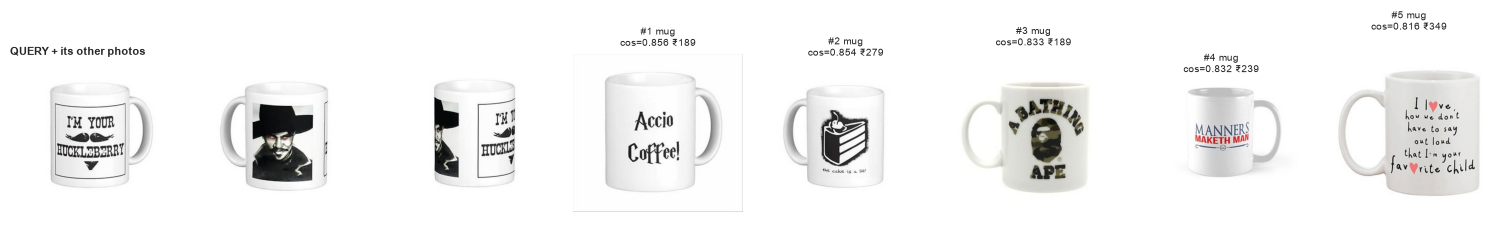

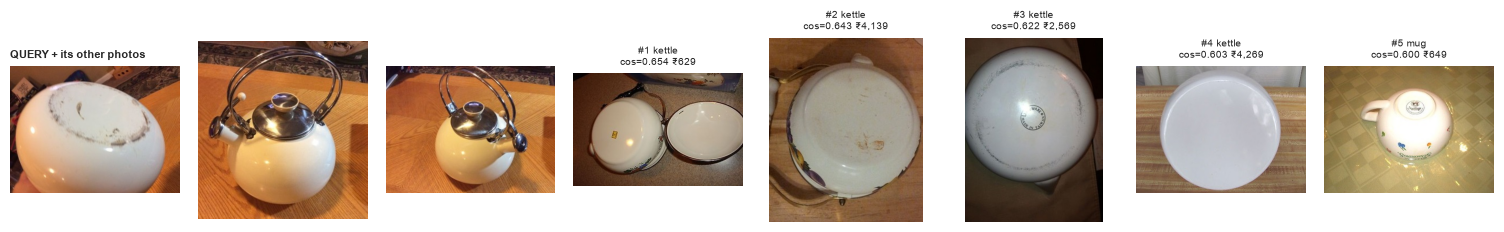

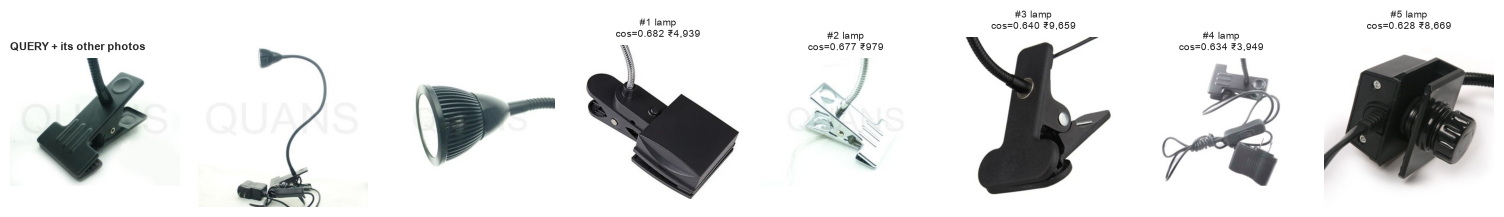

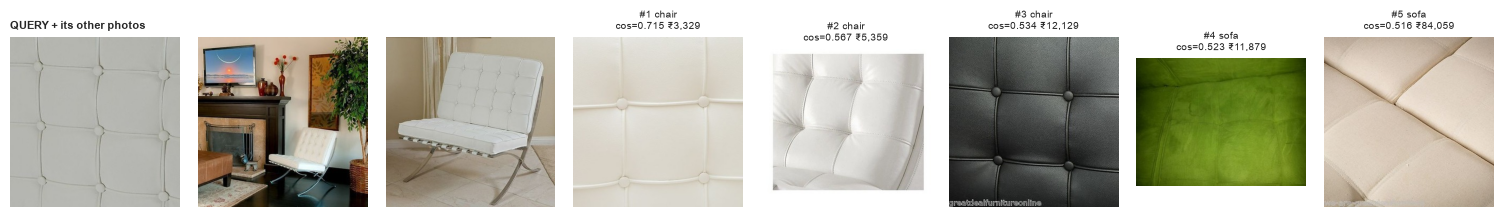

In [15]:
fails = per_query[per_query["product_Hit@10"] == 0].sample(4, random_state=2)
for q in fails["query_row"]:
    row = catalog.iloc[q]
    out = engine.search_image(Image.open(config.CLEAN_IMAGE_DIR / row["image_file"]).convert("RGB"), top_k=6)
    others = [f for f in database.get_product_images(row["product_id"]) if f != row["image_file"]][:2]
    imgs = [Image.open(config.CLEAN_IMAGE_DIR / row["image_file"]).convert("RGB")] + \
           [Image.open(config.CLEAN_IMAGE_DIR / f).convert("RGB") for f in others]
    # Drop the query's own product (it is the photo itself at #1) to show what was retrieved instead.
    res = out.results[out.results["product_id"] != row["product_id"]].head(5).copy()
    res["rank"] = range(1, len(res) + 1)
    show_results(imgs, res, "QUERY + its other photos")

**What the failure analysis shows**

* **More photos per listing → higher recall:** 0.42 when the product has just one other
  photo, up to ~0.68 with 8 or more. More views mean a higher chance that at least one is
  close to the query.
* **The query's view index barely matters** (0.62 for the main photo → 0.58 for later
  photos), so the system isn't only good at matching "hero" shots.
* **The remaining misses are mostly look-alikes and close-ups:**
  * **Look-alikes:** generic white mugs with different prints, the same style of clip lamp
    from several sellers. The retrieved product is often an equally valid recommendation;
    the benchmark just counts it as wrong.
  * **Texture close-ups:** a tufted-leather detail shot matches other leather close-ups,
    because there is no product shape in the frame to anchor on.

These failures come from generic ImageNet features, not from the search engine. The way to
fix them is product-specific fine-tuning (see the README's future work).

## 6. ANN fidelity, latency and upload robustness

In [16]:
rows = []
for m, r in models.items():
    up = r["upload_robustness"]
    rows.append({"model": m, "dim": r["embedding_dim"],
                 "HNSW vs exact overlap@10": r["ann_fidelity@10"],
                 "flat ms/query": r["latency"]["flat"]["mean_ms"],
                 "HNSW ms/query": r["latency"]["hnsw"]["mean_ms"],
                 "HNSW p95 ms": r["latency"]["hnsw"]["p95_ms"],
                 "upload: correct product @1": up["exact_product_hit@1"],
                 "upload: correct product @5": up["exact_product_hit@5"],
                 "upload: category P@10": up["category_P@10"],
                 "CNN ms/image (median)": up["cnn_embed_ms_per_image"],
                 "search + rank ms (median)": up["search_and_rank_ms"]})
pd.DataFrame(rows).set_index("model").T

model,resnet50,efficientnet_b0
dim,2048.0000,1280.0000
HNSW vs exact overlap@10,0.9998,0.9998
flat ms/query,16.0175,10.8847
HNSW ms/query,0.9199,0.6724
HNSW p95 ms,1.4160,1.0736
upload: correct product @1,0.9900,0.9900
upload: correct product @5,0.9933,0.9933
upload: category P@10,0.7133,0.7240
CNN ms/image (median),13.5900,19.0200
search + rank ms (median),4.4500,4.5000


* **ANN fidelity:** HNSW returns **99.98 %** of the exact top-10, so approximate search costs
  essentially nothing in accuracy.
* **Latency:** HNSW search takes **~0.9 ms** per query (p95 ~1.4 ms) versus ~16 ms for brute
  force. Single-image CNN embedding takes ~14 ms (median, GPU) and grouping/ranking takes
  ~4-5 ms, so an end-to-end upload search finishes in a few tens of milliseconds.
* **Upload robustness:** for 300 catalog photos that were randomly cropped, rotated and
  colour-shifted, the **correct product is ranked #1 in 99 %** of cases.

## 7. Conclusions

| Requirement (project brief) | Result |
|---|---|
| Pretrained CNN, classifier removed, dense embedding | ResNet50 → 2048-d (GeM) and EfficientNet-B0 → 1280-d, L2-normalised |
| FAISS ANN index | HNSW (M=32, efSearch=128): 99.98 % of exact top-10 |
| Cosine Top-K search, millisecond-level | ~1-1.6 ms per HNSW query over 58,891 vectors (vs ~16-38 ms brute force) |
| Ranking & filtering | one result per product, ranked by similarity; category / price / stock filters inside FAISS |
| **Precision@K** | category P@1 **0.917**, P@10 **0.799** (random 0.088); product P@1 **0.602** |
| **Recall@K** | product Recall@1 **0.602**, @10 **0.761**, @20 **0.797** (SOP hit-rate definition) |
| Visual inspection | same-listing photos from other angles retrieved first; misses are look-alikes, close-ups or scene matches |
| Robustness | distorted shopper-style photo → correct product #1 in 99 % of cases |

**ResNet50 (GeM) + HNSW** is the configuration served by the Streamlit app.